In [ ]:
#https://www.usgs.gov/programs/earthquake-hazards/earthquakes
#https://earthquake.usgs.gov/earthquakes/search/
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv('/content/terremotos.csv')
df.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2026-10-03T13:51:11.299Z,-27.4948,-179.4827,453.487,4.5,mb,29,112,2.217,0.82,...,2026-10-03T14:21:50.040Z,Kermadec Islands region,earthquake,14.61,12.190,0.103,28,reviewed,us,us
1,2026-10-03T06:05:21.157Z,29.2210,130.6125,37.466,4.8,mb,70,101,2.285,0.82,...,2026-10-03T06:25:52.040Z,"112 km S of Koshima, Japan",earthquake,6.53,7.001,0.060,86,reviewed,us,us
2,2026-10-03T02:59:06.296Z,52.0836,160.4217,10.000,5.0,mb,64,135,1.952,0.88,...,2026-10-03T03:14:19.040Z,"163 km SE of Petropavlovsk-Kamchatsky, Russia",earthquake,9.62,1.892,0.052,119,reviewed,us,us
3,2026-10-03T00:11:38.239Z,31.2953,130.6093,126.853,4.5,mb,58,122,0.252,0.98,...,2026-10-03T06:53:18.579Z,"7 km NNW of Ibusuki, Japan",earthquake,8.49,4.423,0.060,81,reviewed,us,us
4,2026-10-03T00:01:38.784Z,51.9749,159.2731,38.690,4.8,mb,59,122,13.625,0.84,...,2026-10-03T01:19:10.040Z,"121 km SSE of Vilyuchinsk, Russia",earthquake,12.30,7.590,0.064,76,reviewed,us,us


## Vamos trabalhar só com algumas colunas do banco de dados

In [2]:
df = pd.read_csv("/content/terremotos.csv", usecols=['time','latitude', 'longitude','mag','place'])
df

,time,latitude,longitude,mag,place
0,2026-10-03T13:51:11.299Z,-27.4948,-179.4827,4.5,Kermadec Islands region
1,2026-10-03T06:05:21.157Z,29.2210,130.6125,4.8,"112 km S of Koshima, Japan"
2,2026-10-03T02:59:06.296Z,52.0836,160.4217,5.0,"163 km SE of Petropavlovsk-Kamchatsky, Russia"
3,2026-10-03T00:11:38.239Z,31.2953,130.6093,4.5,"7 km NNW of Ibusuki, Japan"
4,2026-10-03T00:01:38.784Z,51.9749,159.2731,4.8,"121 km SSE of Vilyuchinsk, Russia"
...,...,...,...,...,...
528,2026-09-03T05:10:19.410Z,-55.8597,-26.1421,4.5,South Sandwich Islands region
529,2026-09-03T04:43:43.775Z,-55.9730,-26.1660,4.5,South Sandwich Islands region
530,2026-09-03T02:37:33.500Z,14.5039,56.0984,4.5,Owen Fracture Zone region
531,2026-09-03T00:09:29.545Z,-17.6131,-178.1425,4.5,"273 km E of Levuka, Fiji"


Veja que a célula da data está muito poluída. Só queremos a data ano, mes e dia

In [3]:
import pandas as pd


df['data'] = pd.to_datetime(df['time'])


df['data'] = df['data'].dt.strftime('%Y-%m-%d')

df

,time,latitude,longitude,mag,place,data
0,2026-10-03T13:51:11.299Z,-27.4948,-179.4827,4.5,Kermadec Islands region,2026-10-03
1,2026-10-03T06:05:21.157Z,29.2210,130.6125,4.8,"112 km S of Koshima, Japan",2026-10-03
2,2026-10-03T02:59:06.296Z,52.0836,160.4217,5.0,"163 km SE of Petropavlovsk-Kamchatsky, Russia",2026-10-03
3,2026-10-03T00:11:38.239Z,31.2953,130.6093,4.5,"7 km NNW of Ibusuki, Japan",2026-10-03
4,2026-10-03T00:01:38.784Z,51.9749,159.2731,4.8,"121 km SSE of Vilyuchinsk, Russia",2026-10-03
...,...,...,...,...,...,...
528,2026-09-03T05:10:19.410Z,-55.8597,-26.1421,4.5,South Sandwich Islands region,2026-09-03
529,2026-09-03T04:43:43.775Z,-55.9730,-26.1660,4.5,South Sandwich Islands region,2026-09-03
530,2026-09-03T02:37:33.500Z,14.5039,56.0984,4.5,Owen Fracture Zone region,2026-09-03
531,2026-09-03T00:09:29.545Z,-17.6131,-178.1425,4.5,"273 km E of Levuka, Fiji",2026-09-03


## Criando o grafo cujos nós são as posições (latitude e longitude) e as arestas correspondem às localidades que tiveram terremotos em no máximo 2 dias de diferença

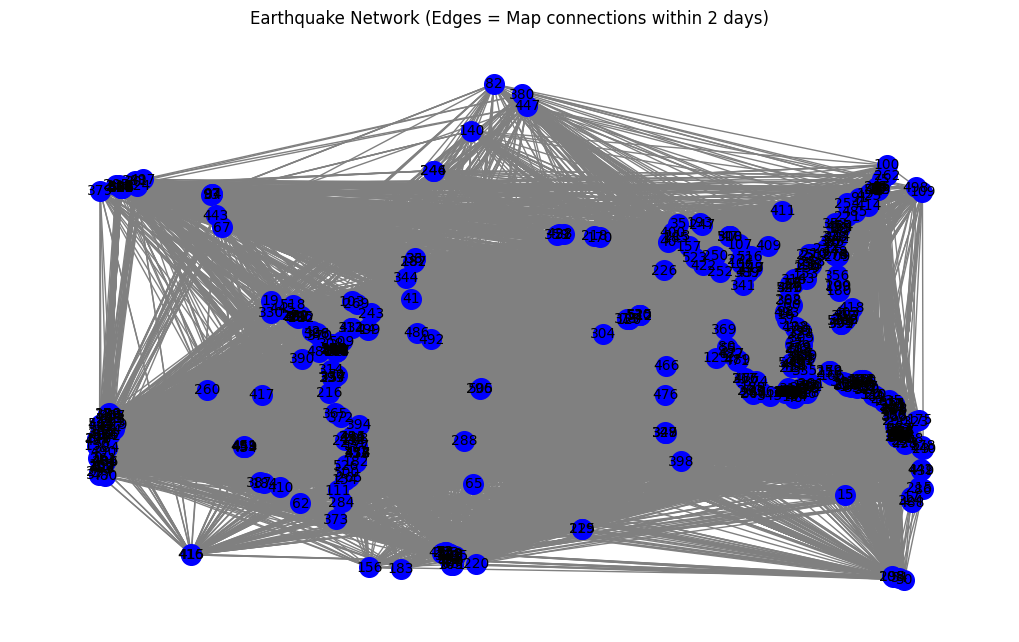

In [4]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


dates_dt = pd.to_datetime(df['data'])

G = nx.Graph()

for idx, row in df.iterrows():

    node_id = idx
    G.add_node(node_id, pos=(row['longitude'], row['latitude']), time=row['data'])

for i in range(len(df)):
    for j in range(i + 1, len(df)):

        time_diff = abs((dates_dt[j] - dates_dt[i]).days)

        # cria a aresta se os terremotos ocorreram em 2 dias ou menos
        if time_diff <= 2:
            G.add_edge(i, j)
        else:
            # Como os dados de terremotos geralmente vêm ordenados por tempo decrescente,
            # podemos continuar para verificar outros pares, ou se tiver certeza de que estão estritamente ordenados,

            pass

pos = nx.get_node_attributes(G, 'pos')

plt.figure(figsize=(10, 6))
nx.draw(G, pos, with_labels=True, node_color='blue', node_size=200, edge_color='gray', font_size=10)
plt.title("Earthquake Network (Edges = Map connections within 2 days)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()

## Colocando os nomes dos países

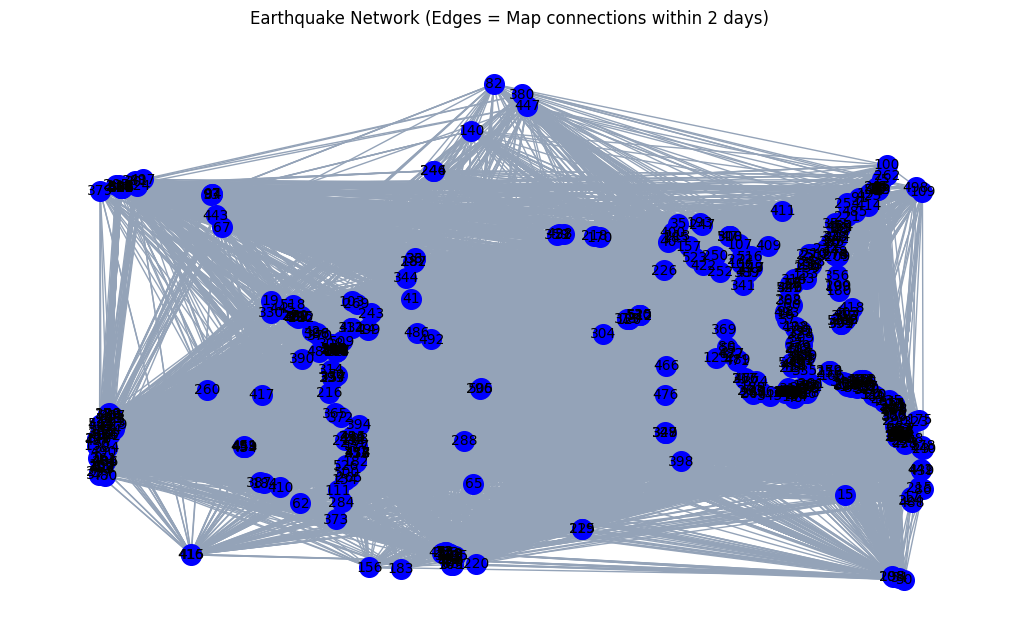

In [5]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


dates_dt = pd.to_datetime(df['data'])
df['pais'] = df['place'].apply(lambda x: x.split(',')[-1].strip() if ',' in str(x) else str(x))

G = nx.Graph()

for idx, row in df.iterrows():

    node_id = idx
    G.add_node(node_id, pos=(row['longitude'], row['latitude']), time=row['data'])

for i in range(len(df)):
    for j in range(i + 1, len(df)):

        time_diff = abs((dates_dt[j] - dates_dt[i]).days)

        # cria a aresta se os terremotos ocorreram em 2 dias ou menos
        if time_diff <= 2:
            G.add_edge(i, j)
        else:
            # Como os dados de terremotos geralmente vêm ordenados por tempo decrescente,
            # podemos continuar para verificar outros pares, ou se tiver certeza de que estão estritamente ordenados,

            pass

pos = nx.get_node_attributes(G, 'pos')

plt.figure(figsize=(10, 6))
nx.draw(G, pos, with_labels=True, node_color='blue', node_size=200, edge_color='#94a3b8', font_size=10)
plt.title("Earthquake Network (Edges = Map connections within 2 days)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()



/tmp/ipykernel_1213/2593443349.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab10', len(paises_unicos))
/tmp/ipykernel_1213/2593443349.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


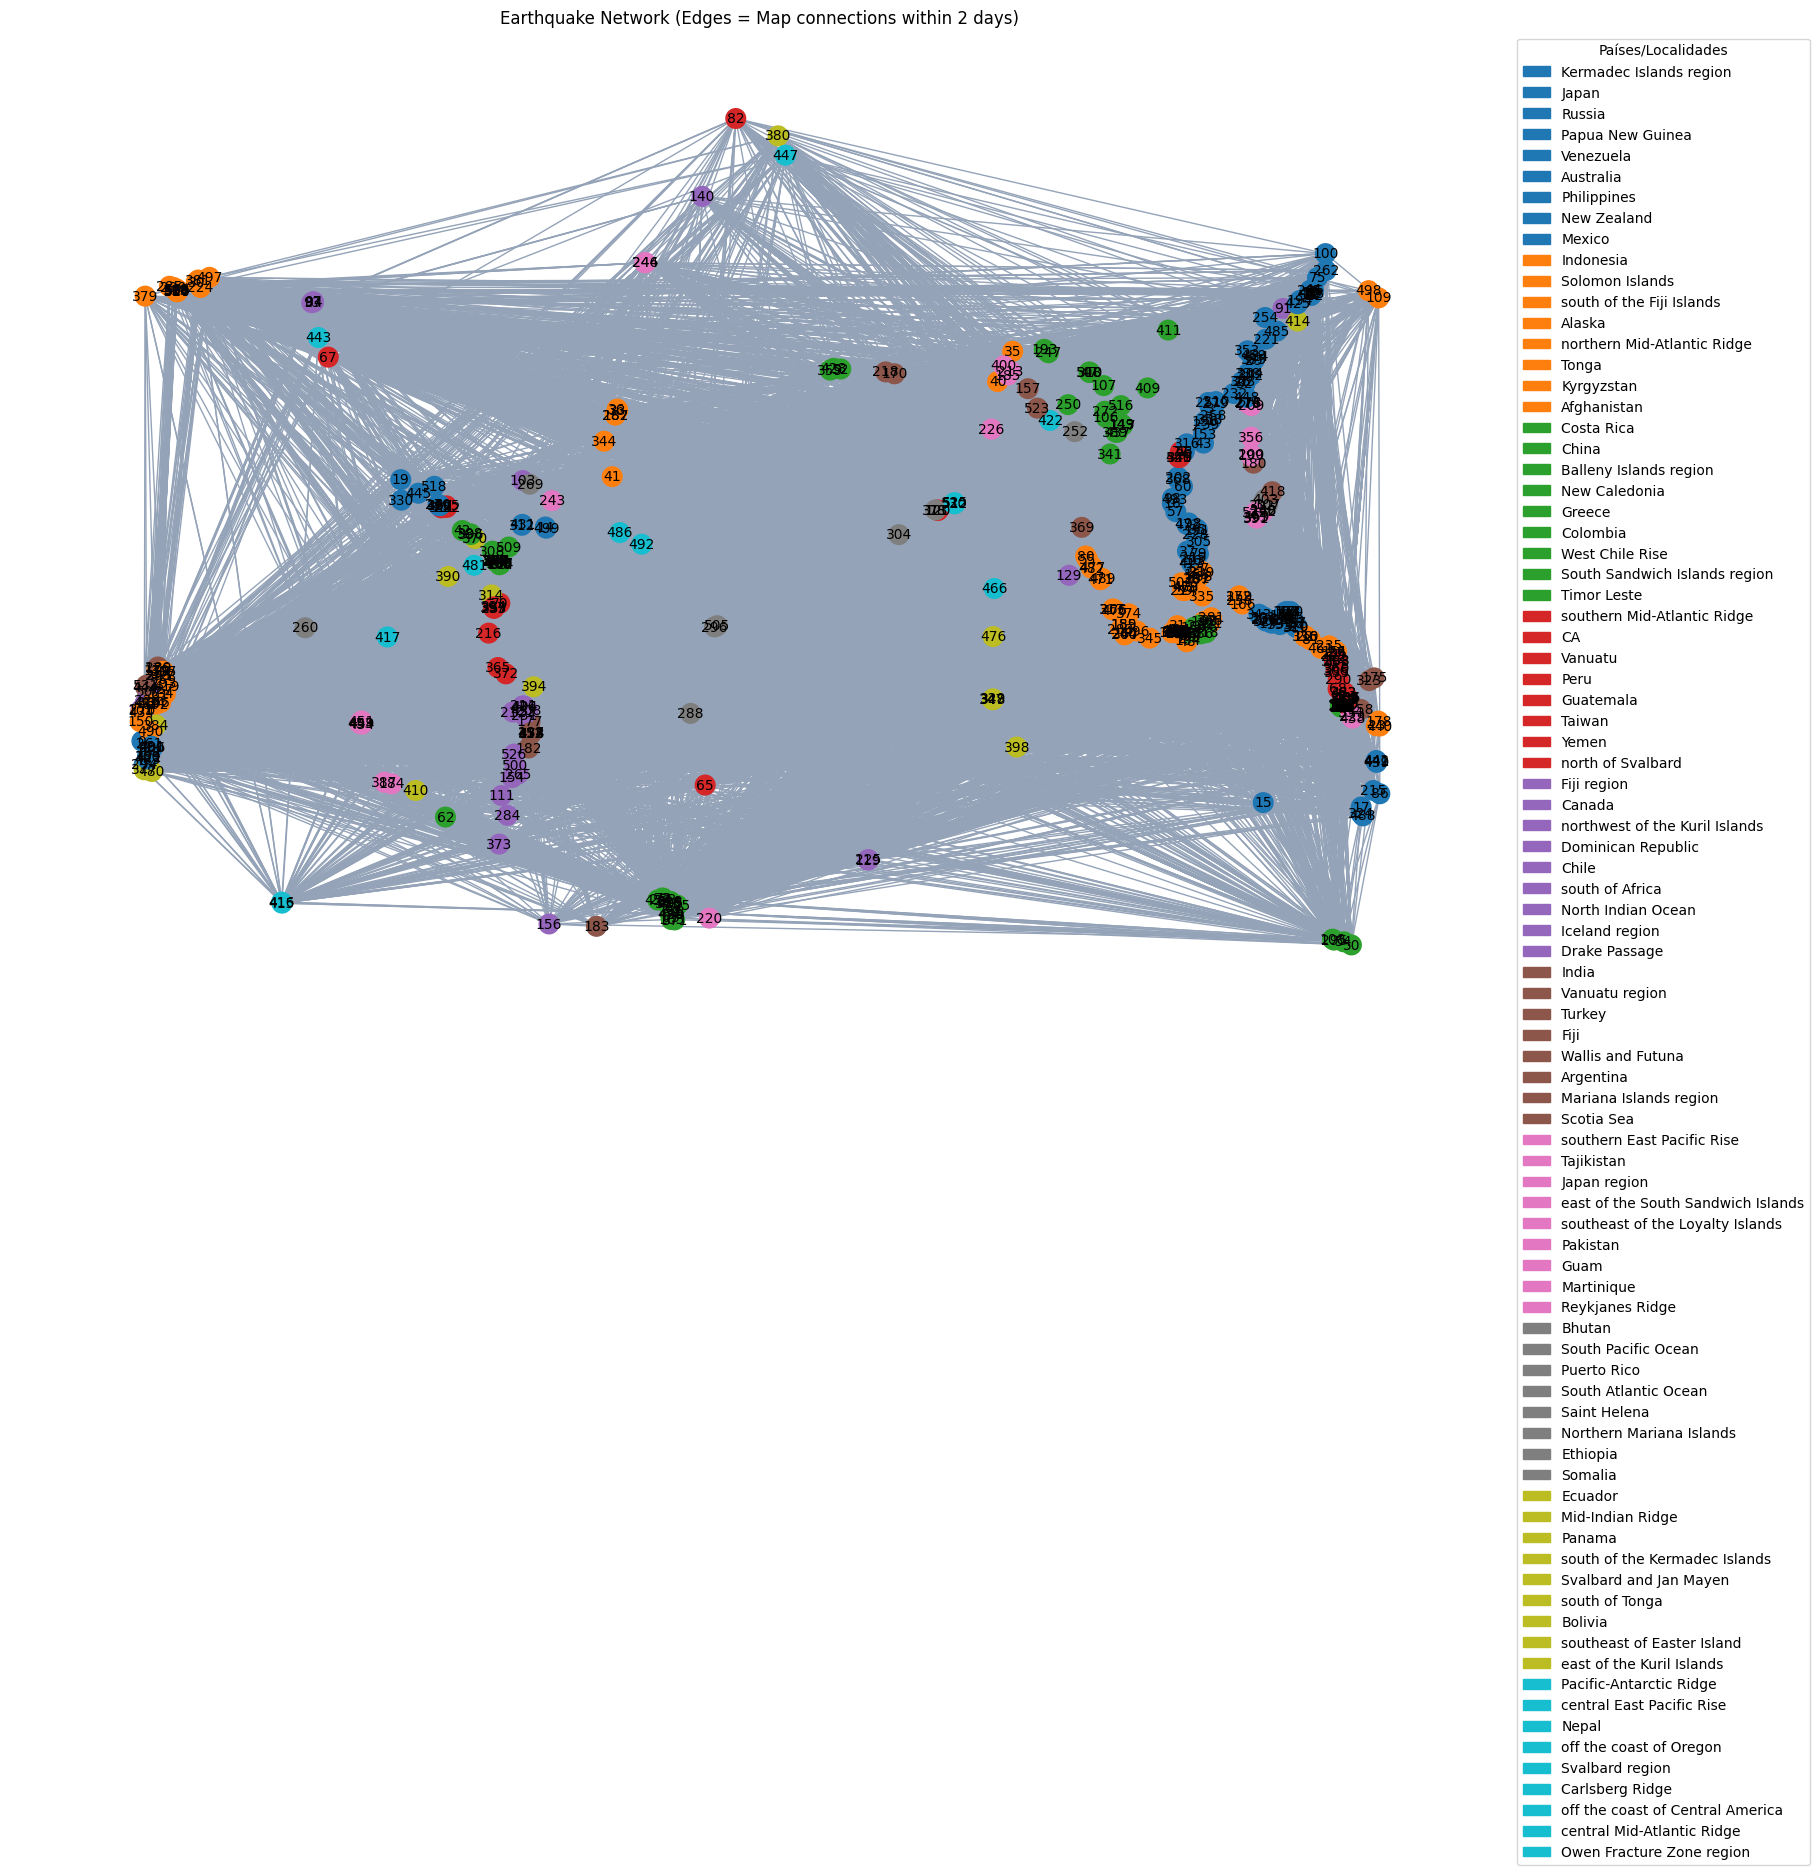

In [6]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches  # Necessário para a legenda personalizada

dates_dt = pd.to_datetime(df['data'])
df['pais'] = df['place'].apply(lambda x: x.split(',')[-1].strip() if ',' in str(x) else str(x))

G = nx.Graph()

# 1. Adicionar nós e salvar o país como atributo do nó
for idx, row in df.iterrows():
    G.add_node(
        idx,
        pos=(row['longitude'], row['latitude']),
        time=row['data'],
        pais=row['pais']  # Salvando o país no nó
    )

# Criação das arestas (mantendo a sua lógica de 2 dias ou menos)
for i in range(len(df)):
    for j in range(i + 1, len(df)):
        time_diff = abs((dates_dt[j] - dates_dt[i]).days)
        if time_diff <= 2:
            G.add_edge(i, j)

# 2. Mapeamento de Cores por País
paises_unicos = df['pais'].unique()
# Usando a paleta 'tab10' ou 'tab20' dependendo de quantos países você tem
cmap = plt.cm.get_cmap('tab10', len(paises_unicos))
color_map_pais = {pais: cmap(i) for i, pais in enumerate(paises_unicos)}

# Criar a lista de cores dos nós baseada na ordem dos nós do grafo
node_colors = [color_map_pais[G.nodes[node]['pais']] for node in G.nodes()]

# Configuração do gráfico
pos = nx.get_node_attributes(G, 'pos')
plt.figure(figsize=(15, 10)) # Aumentei um pouco para acomodar a legenda

# 3. Desenhar o grafo com o mapeamento de cores atualizado
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=node_colors,  # Lista de cores gerada
    node_size=200,
    edge_color='#94a3b8',
    font_size=10
)

# 4. Construir a legenda manualmente
legend_handles = []
for pais, cor in color_map_pais.items():
    # Cria um círculo colorido para cada país
    patch = mpatches.Patch(color=cor, label=pais)
    legend_handles.append(patch)

# Adiciona a legenda na lateral externa do gráfico
plt.legend(handles=legend_handles, title="Países/Localidades", loc='upper left', bbox_to_anchor=(1, 1))

plt.title("Earthquake Network (Edges = Map connections within 2 days)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)

# Ajusta o layout para a legenda não cortar
plt.tight_layout()
plt.show()


In [7]:
!pip install ffmpeg

  Preparing metadata (setup.py) ... done
  Created wheel for ffmpeg: filename=ffmpeg-1.4-py3-none-any.whl size=6126 sha256=b5e5b82088188f43eb44ea65580c0222036e94263fd820e332002b871bd72bd1
  Stored in directory: /root/.cache/pip/wheels/a4/04/6c/ab972358c48aedc5be02f1d28968f2baa491a2837270932043
Successfully built ffmpeg


Erro ao salvar o vídeo: Command '['/usr/bin/ffmpeg', '-f', 'rawvideo', '-vcodec', 'rawvideo', '-s', '1200x600', '-pix_fmt', 'rgba', '-framerate', '2', '-loglevel', 'error', '-i', 'pipe:', '-vcodec', 'h264', '-pix_fmt', 'yuv420p', '-y', 'rede_terremotos.mp4']' returned non-zero exit status 255.
Por favor, verifique se o ffmpeg está instalado corretamente rodando '!apt-get install -y ffmpeg' em uma célula anterior.


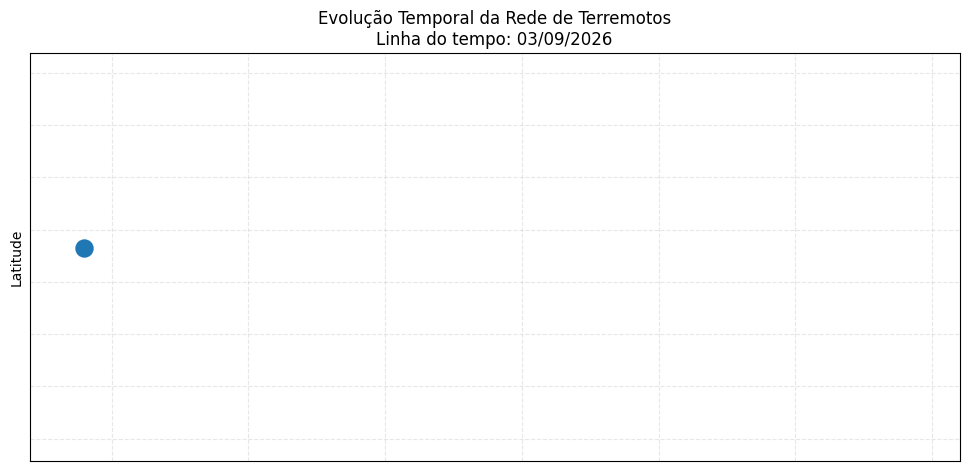

In [8]:
%matplotlib inline

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.dates as mdates

# Força o Matplotlib a encontrar o ffmpeg no caminho correto do Colab/Ubuntu
plt.rcParams['animation.ffmpeg_path'] = '/usr/bin/ffmpeg'

# 1. Preparação dos dados (Garantir ordenação cronológica)
df['data'] = pd.to_datetime(df['data'])
df = df.sort_values('data').reset_index(drop=True)
df['pais'] = df['place'].apply(lambda x: x.split(',')[-1].strip() if ',' in str(x) else str(x))

# 2. Configuração de Cores por País
paises_unicos = df['pais'].unique()
cmap = plt.colormaps.get_cmap('tab10').resampled(len(paises_unicos))
color_map_pais = {pais: cmap(i) for i, pais in enumerate(paises_unicos)}

# Configuração inicial da figura do Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))

# Grafo vazio que será preenchido frame a frame
G_anim = nx.Graph()

# Definir os limites estáticos dos eixos para o gráfico não ficar pulando
xmin = mdates.date2num(df['data'].min() - pd.Timedelta(days=2))
xmax = mdates.date2num(df['data'].max() + pd.Timedelta(days=2))
ax.set_xlim(xmin, xmax)
ax.set_ylim(df['latitude'].min() - 5, df['latitude'].max() + 5)

# Formatação das datas no eixo X
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())

# Função de atualização para cada frame da animação
def update(frame):
    # Se for o primeiro frame, limpa o grafo global para evitar lixo de execuções passadas
    if frame == 0:
        G_anim.clear()

    # Limpa o eixo mantendo as configurações de limites e grades
    ax.clear()
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(df['latitude'].min() - 5, df['latitude'].max() + 5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_ylabel("Latitude")

    # Pega o terremoto atual do frame
    row = df.iloc[frame]
    current_date = row['data']

    # Título dinâmico mostrando a linha do tempo avançando
    ax.set_title(f"Evolução Temporal da Rede de Terremotos\nLinha do tempo: {current_date.strftime('%d/%m/%Y')}", fontsize=12)

    # Adiciona o novo nó ao grafo (Convertendo a data com mdates.date2num)
    x_coord = mdates.date2num(row['data'])
    G_anim.add_node(frame, pos=(x_coord, row['latitude']), pais=row['pais'], data=row['data'])

    # Verifica e adiciona arestas apenas com os nós que JÁ EXISTEM no grafo
    for node in list(G_anim.nodes()):
        if node != frame:
            time_diff = abs((current_date - G_anim.nodes[node]['data']).days)
            if time_diff <= 2:
                G_anim.add_edge(frame, node)

    # Extrai posições e cores dos nós atuais
    pos = nx.get_node_attributes(G_anim, 'pos')
    node_colors = [color_map_pais[G_anim.nodes[n]['pais']] for n in G_anim.nodes()]

    # Desenha o estado atual do grafo neste frame específico
    nx.draw_networkx_edges(G_anim, pos, edge_color='#cbd5e1', alpha=0.6, ax=ax)
    nx.draw_networkx_nodes(G_anim, pos, node_color=node_colors, node_size=150, ax=ax)

    # Inclina as datas do eixo X para melhor leitura
    fig.autofmt_xdate()

# Criando a animação
ani = animation.FuncAnimation(fig, update, frames=len(df), interval=500, repeat=False)

# Salva o arquivo de vídeo MP4 com tratamento de erro amigável
try:
    ani.save('rede_terremotos.mp4', writer='ffmpeg', fps=2)
    print("Animação salva com sucesso em 'rede_terremotos.mp4'!")
except Exception as e:
    print(f"Erro ao salvar o vídeo: {e}")
    print("Por favor, verifique se o ffmpeg está instalado corretamente rodando '!apt-get install -y ffmpeg' em uma célula anterior.")

# Fecha a figura de maneira segura tratando qualquer erro de callback do Matplotlib
#try:
 #   plt.close(fig)
#except Exception:
 #  pass

In [9]:
from IPython.display import HTML, display
from base64 import b64encode

# Abre o vídeo gerado e o codifica em base64 para exibição direta no navegador
mp4 = open('rede_terremotos.mp4','rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()

# Exibe o player de vídeo de forma explícita na célula utilizando display()
display(HTML(f"""
<video width="800" height="400" controls>
      <source src="{data_url}" type="video/mp4">
</video>
"""))

## Medidas de centralidade temporais

In [10]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches  # Necessário para a legenda personalizada

dates_dt = pd.to_datetime(df['data'])
df['pais'] = df['place'].apply(lambda x: x.split(',')[-1].strip() if ',' in str(x) else str(x))

G_temporal = nx.DiGraph()

for idx, row in df.iterrows():
    G_temporal.add_node(
        idx,
        pos=(row['longitude'], row['latitude']),
        time=pd.to_datetime(row['data']),
        pais=row['pais']
    )

for i in range(len(df)):
    for j in range(i + 1, len(df)):

        t_i = pd.to_datetime(df.iloc[i]['data'])
        t_j = pd.to_datetime(df.iloc[j]['data'])

        time_diff = (t_j - t_i).total_seconds() / (24 * 3600)

        if 0 <= time_diff <= 2:
            G_temporal.add_edge(i, j)

degree_centrality = nx.degree_centrality(G_temporal)

in_degree = dict(G_temporal.in_degree())
out_degree = dict(G_temporal.out_degree())

betweenness = nx.betweenness_centrality(G_temporal)

pagerank = nx.pagerank(G_temporal)



In [11]:
df['in_degree'] = df.index.map(in_degree)
df['out_degree'] = df.index.map(out_degree)
df['betweenness'] = df.index.map(betweenness)
df['pagerank'] = df.index.map(pagerank)

print('in degree',in_degree)


in degree {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14, 15: 15, 16: 16, 17: 17, 18: 18, 19: 19, 20: 20, 21: 21, 22: 22, 23: 23, 24: 24, 25: 25, 26: 26, 27: 27, 28: 28, 29: 29, 30: 30, 31: 31, 32: 32, 33: 33, 34: 34, 35: 35, 36: 36, 37: 37, 38: 38, 39: 39, 40: 40, 41: 41, 42: 42, 43: 43, 44: 44, 45: 45, 46: 46, 47: 47, 48: 48, 49: 49, 50: 50, 51: 51, 52: 52, 53: 53, 54: 54, 55: 55, 56: 56, 57: 57, 58: 58, 59: 59, 60: 60, 61: 61, 62: 62, 63: 63, 64: 64, 65: 65, 66: 66, 67: 67, 68: 68, 69: 69, 70: 36, 71: 37, 72: 38, 73: 39, 74: 40, 75: 41, 76: 42, 77: 43, 78: 44, 79: 45, 80: 46, 81: 47, 82: 48, 83: 49, 84: 50, 85: 51, 86: 52, 87: 53, 88: 54, 89: 41, 90: 42, 91: 43, 92: 44, 93: 45, 94: 46, 95: 47, 96: 26, 97: 27, 98: 28, 99: 29, 100: 30, 101: 31, 102: 32, 103: 33, 104: 34, 105: 35, 106: 36, 107: 37, 108: 38, 109: 39, 110: 40, 111: 41, 112: 42, 113: 43, 114: 44, 115: 26, 116: 27, 117: 28, 118: 29, 119: 30, 120: 31, 121: 32, 122: 33, 12

In [13]:
df['data'] = pd.to_datetime(df['data'])

df['month'] = df['data'].dt.to_period('M')

results = []

for month, group in df.groupby('month'):

    G_month = nx.Graph()

    for idx, row in group.iterrows():
        G_month.add_node(idx)

    indices = list(group.index)

    for a in range(len(indices)):
        for b in range(a + 1, len(indices)):

            i = indices[a]
            j = indices[b]

            diff = abs(
                (df.loc[j, 'data'] - df.loc[i, 'data']).total_seconds()
            ) / 86400

            if diff <= 2:
                G_month.add_edge(i, j)

    if len(G_month) > 1:

        centrality = nx.degree_centrality(G_month)

        for node, value in centrality.items():
            results.append({
                'month': month,
                'node': node,
                'degree_centrality': value
            })

centrality_df = pd.DataFrame(results)


In [14]:
centrality_df

,month,node,degree_centrality
0,2026-09,0,0.140816
1,2026-09,1,0.140816
2,2026-09,2,0.140816
3,2026-09,3,0.140816
4,2026-09,4,0.140816
...,...,...,...
528,2026-10,528,1.000000
529,2026-10,529,1.000000
530,2026-10,530,1.000000
531,2026-10,531,1.000000


In [15]:
centrality_df = pd.DataFrame(results)


In [16]:
centrality_df['place'] = centrality_df['node'].map(df['place'])
centrality_df['pais'] = centrality_df['node'].map(df['pais'])
centrality_df['data'] = centrality_df['node'].map(df['data'])


In [17]:
centrality_df = centrality_df[
    ['month', 'node', 'data', 'place', 'pais', 'degree_centrality']
]


In [ ]:
centrality_df

,month,node,data,place,pais,degree_centrality
0,2026-09,42,2026-09-30,"94 km SW of Tamarindo, Costa Rica",Costa Rica,0.118367
1,2026-09,43,2026-09-30,"131 km SE of Itoman, Japan",Japan,0.118367
2,2026-09,44,2026-09-30,"136 km SE of Petropavlovsk-Kamchatsky, Russia",Russia,0.118367
3,2026-09,45,2026-09-30,"142 km SE of Petropavlovsk-Kamchatsky, Russia",Russia,0.118367
4,2026-09,46,2026-09-30,"83 km S of Yonakuni, Japan",Japan,0.118367
...,...,...,...,...,...,...
528,2026-10,37,2026-10-01,"38 km WSW of Palimbang, Philippines",Philippines,1.000000
529,2026-10,38,2026-10-01,"272 km WSW of Tual, Indonesia",Indonesia,1.000000
530,2026-10,39,2026-10-01,"45 km ENE of Luwuk, Indonesia",Indonesia,1.000000
531,2026-10,40,2026-10-01,"7 km ESE of Baghlān, Afghanistan",Afghanistan,1.000000


In [18]:
results = []

for month, group in df.groupby('month'):

    G_month = nx.Graph()

    for idx, row in group.iterrows():
        G_month.add_node(
            idx,
            place=row['place'],
            pais=row['pais'],
            data=row['data']
        )

    indices = list(group.index)

    for a in range(len(indices)):
        for b in range(a + 1, len(indices)):

            i = indices[a]
            j = indices[b]

            diff = abs(
                (df.loc[j, 'data'] - df.loc[i, 'data']).total_seconds()
            ) / 86400

            if diff <= 2:
                G_month.add_edge(i, j)

    if len(G_month) > 1:

        degree = nx.degree_centrality(G_month)
        betweenness = nx.betweenness_centrality(G_month)
        closeness = nx.closeness_centrality(G_month)

        for node in G_month.nodes():

            results.append({
                'month': month,
                'node': node,
                'data': df.loc[node, 'data'],
                'place': df.loc[node, 'place'],
                'pais': df.loc[node, 'pais'],
                'degree_centrality': degree[node],
                'betweenness_centrality': betweenness[node],
                'closeness_centrality': closeness[node]
            })

centrality_df = pd.DataFrame(results)


In [19]:
centrality_df

,month,node,data,place,pais,degree_centrality,betweenness_centrality,closeness_centrality
0,2026-09,0,2026-09-03,"132 km WSW of Merizo Village, Guam",Guam,0.140816,0.0,0.140764
1,2026-09,1,2026-09-03,Owen Fracture Zone region,Owen Fracture Zone region,0.140816,0.0,0.140764
2,2026-09,2,2026-09-03,"83 km SSW of Nikolski, Alaska",Alaska,0.140816,0.0,0.140764
3,2026-09,3,2026-09-03,"92 km SSW of Nikolski, Alaska",Alaska,0.140816,0.0,0.140764
4,2026-09,4,2026-09-03,"11 km NNE of Jordán, Colombia",Colombia,0.140816,0.0,0.140764
...,...,...,...,...,...,...,...,...
528,2026-10,528,2026-10-03,"121 km SSE of Vilyuchinsk, Russia",Russia,1.000000,0.0,1.000000
529,2026-10,529,2026-10-03,"7 km NNW of Ibusuki, Japan",Japan,1.000000,0.0,1.000000
530,2026-10,530,2026-10-03,"163 km SE of Petropavlovsk-Kamchatsky, Russia",Russia,1.000000,0.0,1.000000
531,2026-10,531,2026-10-03,"112 km S of Koshima, Japan",Japan,1.000000,0.0,1.000000


In [21]:
centrality_df['pagerank'] = centrality_df['node'].map(df['pagerank'])

centrality_measures = [
    'degree_centrality',
    'betweenness_centrality',
    'closeness_centrality'
]

top10_list = []

for measure in centrality_measures:
    top10 = centrality_df.nlargest(10, measure).copy()
    top10['centrality_measure'] = measure
    top10['rank'] = range(1, len(top10) + 1)

    top10_list.append(top10)

top10_centralities = pd.concat(top10_list, ignore_index=True)
top10_centralities

,month,node,data,place,pais,degree_centrality,betweenness_centrality,closeness_centrality,pagerank,centrality_measure,rank
0,2026-10,491,2026-10-01,"0 km NNE of Yōkaichiba, Japan",Japan,1.000000,0.000000,1.000000,0.001822,degree_centrality,1
1,2026-10,492,2026-10-01,"176 km SE of Lata, Solomon Islands",Solomon Islands,1.000000,0.000000,1.000000,0.001860,degree_centrality,2
2,2026-10,493,2026-10-01,"171 km SE of Lata, Solomon Islands",Solomon Islands,1.000000,0.000000,1.000000,0.001899,degree_centrality,3
3,2026-10,494,2026-10-01,"83 km NE of Ruteng, Indonesia",Indonesia,1.000000,0.000000,1.000000,0.001941,degree_centrality,4
4,2026-10,495,2026-10-01,"108 km ENE of Miyako, Japan",Japan,1.000000,0.000000,1.000000,0.001984,degree_centrality,5
5,2026-10,496,2026-10-01,"127 km S of False Pass, Alaska",Alaska,1.000000,0.000000,1.000000,0.002030,degree_centrality,6
6,2026-10,497,2026-10-01,"176 km NNE of Ruteng, Indonesia",Indonesia,1.000000,0.000000,1.000000,0.002078,degree_centrality,7
7,2026-10,498,2026-10-01,"2 km NE of Satte, Japan",Japan,1.000000,0.000000,1.000000,0.002128,degree_centrality,8
8,2026-10,499,2026-10-01,northern Mid-Atlantic Ridge,northern Mid-Atlantic Ridge,1.000000,0.000000,1.000000,0.002182,degree_centrality,9
9,2026-10,500,2026-10-01,"49 km SSE of Toktogul, Kyrgyzstan",Kyrgyzstan,1.000000,0.000000,1.000000,0.002238,degree_centrality,10
